# Classification training

## Data

In [1]:
from pathlib import Path
import pydicom
from tqdm import tqdm


def check_modality(directory):
    """
    Iterates over all directories in the specified directory and its subdirectories.
    For each directory, checks a single .dcm file to determine if it has a CR or DR modality.
    If the modality is valid, stores all .dcm files from that directory into the list.

    Args:
        directory (str or Path): Path to the root directory containing .dcm files.

    Returns:
        list: A list of paths to .dcm files from directories with valid modality.
    """
    xrays = []
    # Resolve symlinks and get the absolute path
    directory = Path(directory).resolve()

    if not directory.is_dir():
        raise ValueError(
            f"The provided path '{directory}' is not a valid directory.")

    # Iterate over all subdirectories
    for subdir in tqdm([d for d in directory.rglob("*") if d.is_dir()]):
        try:
            # Find a single .dcm file in the current directory
            dcm_files = list(subdir.glob("*.dcm"))
            if not dcm_files:
                continue

            # Check the modality of the first .dcm file
            first_dcm = dcm_files[0]
            dataset = pydicom.dcmread(first_dcm, stop_before_pixels=True)
            modality = dataset.get("Modality", "Unknown")

            # If the modality is valid, add all .dcm files in this directory
            if modality in ["CR", "DR"]:
                dcm_files = [(file, pydicom.dcmread(file, stop_before_pixels=True).get(
                    "ViewPosition")) for file in dcm_files]

                xrays.extend(dcm_files)

        except Exception as e:
            print(f"Error reading files in {subdir}: {e}")

    return xrays


dcms = check_modality("data/LIDC-IDRI")
dcms += check_modality("data/MIDRC-RICORD-1A")
dcms += check_modality("data/MIDRC-RICORD-1C")
dcms

100%|██████████| 2600/2600 [00:01<00:00, 1834.35it/s]


[(PosixPath('/data/LIDC-IDRI/LIDC-IDRI/LIDC-IDRI-0103/01-01-2000-NA-NA-57835/5518.000000-NA-74407/1-1.dcm'),
  'PA'),
 (PosixPath('/data/LIDC-IDRI/LIDC-IDRI/LIDC-IDRI-0076/01-01-2000-NA-NA-71747/3001587.000000-NA-88013/1-1.dcm'),
  None),
 (PosixPath('/data/LIDC-IDRI/LIDC-IDRI/LIDC-IDRI-0119/01-01-2000-NA-NA-83412/5607.000000-W Chest PA-97571/1-1.dcm'),
  'W CHEST PA'),
 (PosixPath('/data/LIDC-IDRI/LIDC-IDRI/LIDC-IDRI-0115/01-01-2000-NA-NA-79031/3240.000000-NA-01933/1-1.dcm'),
  'PA'),
 (PosixPath('/data/LIDC-IDRI/LIDC-IDRI/LIDC-IDRI-0095/01-01-2000-NA-NA-21977/5609.000000-W Chest PA-84162/1-1.dcm'),
  'W CHEST PA'),
 (PosixPath('/data/LIDC-IDRI/LIDC-IDRI/LIDC-IDRI-0121/01-01-2000-NA-NA-60117/3001609.000000-NA-11649/1-1.dcm'),
  None),
 (PosixPath('/data/LIDC-IDRI/LIDC-IDRI/LIDC-IDRI-0072/01-01-2000-NA-CHEST PA - LAT-09981/15478.000000-Chest pa-43410/1-1.dcm'),
  None),
 (PosixPath('/data/LIDC-IDRI/LIDC-IDRI/LIDC-IDRI-0150/01-01-2000-NA-NA-42623/3189.000000-W Chest PA-93281/1-1.dcm'),


In [2]:
filled = [(file, view) for file, view in dcms if view]
filled

[(PosixPath('/data/LIDC-IDRI/LIDC-IDRI/LIDC-IDRI-0103/01-01-2000-NA-NA-57835/5518.000000-NA-74407/1-1.dcm'),
  'PA'),
 (PosixPath('/data/LIDC-IDRI/LIDC-IDRI/LIDC-IDRI-0119/01-01-2000-NA-NA-83412/5607.000000-W Chest PA-97571/1-1.dcm'),
  'W CHEST PA'),
 (PosixPath('/data/LIDC-IDRI/LIDC-IDRI/LIDC-IDRI-0115/01-01-2000-NA-NA-79031/3240.000000-NA-01933/1-1.dcm'),
  'PA'),
 (PosixPath('/data/LIDC-IDRI/LIDC-IDRI/LIDC-IDRI-0095/01-01-2000-NA-NA-21977/5609.000000-W Chest PA-84162/1-1.dcm'),
  'W CHEST PA'),
 (PosixPath('/data/LIDC-IDRI/LIDC-IDRI/LIDC-IDRI-0140/01-01-2000-NA-NA-14219/5583.000000-W Chest PA-46403/1-1.dcm'),
  'W CHEST PA'),
 (PosixPath('/data/LIDC-IDRI/LIDC-IDRI/LIDC-IDRI-0086/01-01-2000-NA-NA-20589/5603.000000-W Chest PA-60852/1-1.dcm'),
  'W CHEST PA'),
 (PosixPath('/data/LIDC-IDRI/LIDC-IDRI/LIDC-IDRI-0141/01-01-2000-NA-NA-85720/5605.000000-W Chest PA-86448/1-1.dcm'),
  'W CHEST PA'),
 (PosixPath('/data/LIDC-IDRI/LIDC-IDRI/LIDC-IDRI-0142/01-01-2000-NA-NA-63790/5592.000000-W Che

In [3]:
empty = [(file, view) for file, view in dcms if not view]
empty

[(PosixPath('/data/LIDC-IDRI/LIDC-IDRI/LIDC-IDRI-0076/01-01-2000-NA-NA-71747/3001587.000000-NA-88013/1-1.dcm'),
  None),
 (PosixPath('/data/LIDC-IDRI/LIDC-IDRI/LIDC-IDRI-0121/01-01-2000-NA-NA-60117/3001609.000000-NA-11649/1-1.dcm'),
  None),
 (PosixPath('/data/LIDC-IDRI/LIDC-IDRI/LIDC-IDRI-0072/01-01-2000-NA-CHEST PA - LAT-09981/15478.000000-Chest pa-43410/1-1.dcm'),
  None),
 (PosixPath('/data/LIDC-IDRI/LIDC-IDRI/LIDC-IDRI-0150/01-01-2000-NA-NA-42623/3189.000000-W Chest PA-93281/1-1.dcm'),
  ''),
 (PosixPath('/data/LIDC-IDRI/LIDC-IDRI/LIDC-IDRI-0029/01-01-2000-NA-NA-85416/3000898.000000-NA-85946/1-1.dcm'),
  None),
 (PosixPath('/data/LIDC-IDRI/LIDC-IDRI/LIDC-IDRI-0078/01-01-2000-NA-NA-01207/3178.000000-W Chest PA-63997/1-1.dcm'),
  ''),
 (PosixPath('/data/LIDC-IDRI/LIDC-IDRI/LIDC-IDRI-0098/01-01-2000-NA-NA-49269/3099.000000-NA-74211/1-2.dcm'),
  ''),
 (PosixPath('/data/LIDC-IDRI/LIDC-IDRI/LIDC-IDRI-0098/01-01-2000-NA-NA-49269/3099.000000-NA-74211/1-1.dcm'),
  ''),
 (PosixPath('/data/L

In [4]:
new_filled = []
for file, view in filled:
    ap = ["AP", "PA"]
    ll = ["LL", "RL"]
    for a in ap:
        if a in view:
            view = "AP"
    for l in ll:
        if l in view:
            view = "LL"
    new_filled.append((file, view))

new_filled

[(PosixPath('/data/LIDC-IDRI/LIDC-IDRI/LIDC-IDRI-0103/01-01-2000-NA-NA-57835/5518.000000-NA-74407/1-1.dcm'),
  'AP'),
 (PosixPath('/data/LIDC-IDRI/LIDC-IDRI/LIDC-IDRI-0119/01-01-2000-NA-NA-83412/5607.000000-W Chest PA-97571/1-1.dcm'),
  'AP'),
 (PosixPath('/data/LIDC-IDRI/LIDC-IDRI/LIDC-IDRI-0115/01-01-2000-NA-NA-79031/3240.000000-NA-01933/1-1.dcm'),
  'AP'),
 (PosixPath('/data/LIDC-IDRI/LIDC-IDRI/LIDC-IDRI-0095/01-01-2000-NA-NA-21977/5609.000000-W Chest PA-84162/1-1.dcm'),
  'AP'),
 (PosixPath('/data/LIDC-IDRI/LIDC-IDRI/LIDC-IDRI-0140/01-01-2000-NA-NA-14219/5583.000000-W Chest PA-46403/1-1.dcm'),
  'AP'),
 (PosixPath('/data/LIDC-IDRI/LIDC-IDRI/LIDC-IDRI-0086/01-01-2000-NA-NA-20589/5603.000000-W Chest PA-60852/1-1.dcm'),
  'AP'),
 (PosixPath('/data/LIDC-IDRI/LIDC-IDRI/LIDC-IDRI-0141/01-01-2000-NA-NA-85720/5605.000000-W Chest PA-86448/1-1.dcm'),
  'AP'),
 (PosixPath('/data/LIDC-IDRI/LIDC-IDRI/LIDC-IDRI-0142/01-01-2000-NA-NA-63790/5592.000000-W Chest PA-21412/1-1.dcm'),
  'AP'),
 (PosixP

In [5]:
from torch.utils.data import Dataset
import torch
import pydicom
import cv2

class XRayDataset(Dataset):
    def __init__(self, dcms, transforms=None):
        self.dcms = dcms
        self.transforms = transforms

    def __len__(self):
        return len(self.dcms)

    def __getitem__(self, idx):
        file, view = self.dcms[idx]
        view = 0 if view == "AP" else 1
        dataset = pydicom.dcmread(file)
        image = dataset.pixel_array
        image = image.astype(float)
        image = torch.from_numpy(image).to(torch.float)
        image = torch.stack([image, image, image])

        # normalize to 0-1 using min and max
        image = image - image.min()
        image = image / image.max()

        if self.transforms:
            image = self.transforms(image)
        return image, view

XRayDataset(new_filled)[0], XRayDataset(new_filled)[0][0].shape

((tensor([[[0.1074, 0.1075, 0.1121,  ..., 0.1335, 0.1262, 0.1226],
           [0.1074, 0.1075, 0.1121,  ..., 0.1335, 0.1263, 0.1226],
           [0.1074, 0.1075, 0.1121,  ..., 0.1335, 0.1263, 0.1225],
           ...,
           [0.2350, 0.2396, 0.2345,  ..., 0.2015, 0.1915, 0.2065],
           [0.2380, 0.2360, 0.2278,  ..., 0.1959, 0.1967, 0.2090],
           [0.2294, 0.2346, 0.2330,  ..., 0.1998, 0.2066, 0.2059]],
  
          [[0.1074, 0.1075, 0.1121,  ..., 0.1335, 0.1262, 0.1226],
           [0.1074, 0.1075, 0.1121,  ..., 0.1335, 0.1263, 0.1226],
           [0.1074, 0.1075, 0.1121,  ..., 0.1335, 0.1263, 0.1225],
           ...,
           [0.2350, 0.2396, 0.2345,  ..., 0.2015, 0.1915, 0.2065],
           [0.2380, 0.2360, 0.2278,  ..., 0.1959, 0.1967, 0.2090],
           [0.2294, 0.2346, 0.2330,  ..., 0.1998, 0.2066, 0.2059]],
  
          [[0.1074, 0.1075, 0.1121,  ..., 0.1335, 0.1262, 0.1226],
           [0.1074, 0.1075, 0.1121,  ..., 0.1335, 0.1263, 0.1226],
           [0.1074, 0.

## Dataloaders

In [20]:
import torchvision.transforms.v2 as transforms
from torch.utils.tensorboard import SummaryWriter
writer = SummaryWriter(comment="ClassifyXRay")

transform = transforms.Compose([
    transforms.ToImagePIL(), # converts to pil so it gets scaled to 0-1 range
    transforms.Compose([transforms.ToImageTensor(), transforms.ConvertImageDtype()]),
    transforms.Resize((224, 224), antialias=True),
    #transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    transforms.RandomHorizontalFlip(),
    transforms.AugMix(),
])
writer.add_image("XRay",XRayDataset(new_filled, transforms=transform)[5][0])
XRayDataset(new_filled, transforms=transform)[0]

(Image([[[0.3206, 0.3271, 0.3269,  ..., 0.0693, 0.0396, 0.0255],
         [0.3216, 0.3286, 0.3285,  ..., 0.0697, 0.0401, 0.0258],
         [0.3223, 0.3293, 0.3286,  ..., 0.0698, 0.0403, 0.0260],
         ...,
         [0.0364, 0.0233, 0.0183,  ..., 0.0514, 0.0530, 0.0529],
         [0.0383, 0.0249, 0.0188,  ..., 0.0515, 0.0523, 0.0523],
         [0.0391, 0.0302, 0.0187,  ..., 0.0511, 0.0519, 0.0520]],
 
        [[0.3206, 0.3271, 0.3269,  ..., 0.0693, 0.0396, 0.0255],
         [0.3216, 0.3286, 0.3285,  ..., 0.0697, 0.0401, 0.0258],
         [0.3223, 0.3293, 0.3286,  ..., 0.0698, 0.0403, 0.0260],
         ...,
         [0.0364, 0.0233, 0.0183,  ..., 0.0514, 0.0530, 0.0529],
         [0.0383, 0.0249, 0.0188,  ..., 0.0515, 0.0523, 0.0523],
         [0.0391, 0.0302, 0.0187,  ..., 0.0511, 0.0519, 0.0520]],
 
        [[0.3206, 0.3271, 0.3269,  ..., 0.0693, 0.0396, 0.0255],
         [0.3216, 0.3286, 0.3285,  ..., 0.0697, 0.0401, 0.0258],
         [0.3223, 0.3293, 0.3286,  ..., 0.0698, 0.0403, 

In [21]:
XRayDataset(new_filled, transforms=transform)[0][0].shape

torch.Size([3, 224, 224])

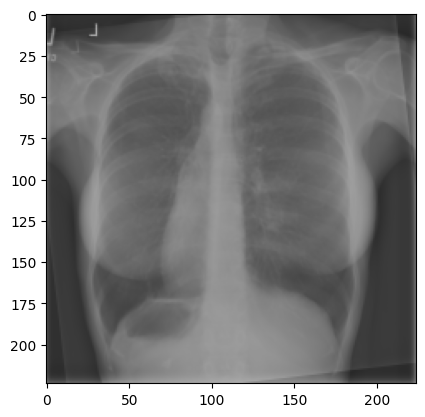

In [29]:
import matplotlib.pyplot as plt

image = XRayDataset(new_filled, transforms=transform)[1][0]
image = image.to("cpu").numpy().transpose((1, 2, 0))
plt.imshow(image)
plt.show()

In [9]:
from torch.utils.data import DataLoader, random_split

dataset = XRayDataset(new_filled, transforms=transform)
# splits into train, val, test
train_size = int(0.8 * len(new_filled))
val_size = (len(new_filled) - train_size) // 2
test_size = len(new_filled) - train_size - val_size
train, val, test = random_split(dataset, [train_size, val_size, test_size])

datasets = {
    "train": train,
    "val": val,
    "test": test
}

dataloaders = {x: DataLoader(datasets[x], batch_size=64, shuffle=True) for x in datasets}

# Model

In [10]:
import timm

timm.list_models("*convnext*")

['convnext_atto',
 'convnext_atto_ols',
 'convnext_base',
 'convnext_femto',
 'convnext_femto_ols',
 'convnext_large',
 'convnext_large_mlp',
 'convnext_nano',
 'convnext_nano_ols',
 'convnext_pico',
 'convnext_pico_ols',
 'convnext_small',
 'convnext_tiny',
 'convnext_tiny_hnf',
 'convnext_xlarge',
 'convnext_xxlarge',
 'convnextv2_atto',
 'convnextv2_base',
 'convnextv2_femto',
 'convnextv2_huge',
 'convnextv2_large',
 'convnextv2_nano',
 'convnextv2_pico',
 'convnextv2_small',
 'convnextv2_tiny']

In [11]:
model = timm.create_model("convnextv2_atto", pretrained=True)
model

ConvNeXt(
  (stem): Sequential(
    (0): Conv2d(3, 40, kernel_size=(4, 4), stride=(4, 4))
    (1): LayerNorm2d((40,), eps=1e-06, elementwise_affine=True)
  )
  (stages): Sequential(
    (0): ConvNeXtStage(
      (downsample): Identity()
      (blocks): Sequential(
        (0): ConvNeXtBlock(
          (conv_dw): Conv2d(40, 40, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3), groups=40)
          (norm): LayerNorm2d((40,), eps=1e-06, elementwise_affine=True)
          (mlp): GlobalResponseNormMlp(
            (fc1): Conv2d(40, 160, kernel_size=(1, 1), stride=(1, 1))
            (act): GELU()
            (drop1): Dropout(p=0.0, inplace=False)
            (grn): GlobalResponseNorm()
            (fc2): Conv2d(160, 40, kernel_size=(1, 1), stride=(1, 1))
            (drop2): Dropout(p=0.0, inplace=False)
          )
          (shortcut): Identity()
          (drop_path): Identity()
        )
        (1): ConvNeXtBlock(
          (conv_dw): Conv2d(40, 40, kernel_size=(7, 7), stride=(1, 1), 

In [12]:
model.head

NormMlpClassifierHead(
  (global_pool): SelectAdaptivePool2d(pool_type=avg, flatten=Identity())
  (norm): LayerNorm2d((320,), eps=1e-06, elementwise_affine=True)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (pre_logits): Identity()
  (drop): Dropout(p=0.0, inplace=False)
  (fc): Linear(in_features=320, out_features=1000, bias=True)
)

In [13]:
in_features = model.head.fc.in_features
model.head.fc = torch.nn.Linear(in_features, 2, bias=True)
model.head

NormMlpClassifierHead(
  (global_pool): SelectAdaptivePool2d(pool_type=avg, flatten=Identity())
  (norm): LayerNorm2d((320,), eps=1e-06, elementwise_affine=True)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (pre_logits): Identity()
  (drop): Dropout(p=0.0, inplace=False)
  (fc): Linear(in_features=320, out_features=2, bias=True)
)

In [14]:
device = "cuda" if torch.cuda.is_available() else "cpu"
model = model.to(device)

# Optimizer

In [15]:
from torch import nn
from torch import optim

epochs = 15
criterion = nn.CrossEntropyLoss()

In [16]:
optimizer = optim.AdamW(
    model.parameters(),
    lr=1e-5,
    betas=(0.9,0.999),
    weight_decay=0.05,
)

In [17]:
scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer=optimizer,
    T_max=epochs
)

## Training

In [18]:
from torch.utils.data import DataLoader
from torcheval.metrics.functional import binary_accuracy, binary_f1_score, binary_precision, binary_recall, binary_auprc, binary_auroc
from tqdm import tqdm
from lib.utils.utils import DataStorer
from torch import nn
import warnings

storer = DataStorer()

def train_one_epoch(
    model: nn.Module,
    dataloaders: dict[str, DataLoader],
    criterion: nn.Module,
    optimizer: optim.Optimizer,
    scheduler: optim.lr_scheduler.LRScheduler,
    epoch: int,
):
    phase = "train"
    model.train()

    pbar = tqdm(dataloaders[phase],f"train - epoch {epoch}")
    
    with torch.set_grad_enabled(phase == "train"):
        running_loss = 0
        for batch in pbar:
            inputs: torch.Tensor = batch[0].to(device)
            targets: torch.Tensor = batch[1].to(device)

            optimizer.zero_grad()
            
            outputs = model(inputs)

            loss = criterion(outputs, targets)
            running_loss += loss
            loss.backward()

            optimizer.step()
        writer.add_scalar("lr", optimizer.param_groups[0]["lr"], epoch)
        storer.store("lr", optimizer.param_groups[0]["lr"])
        scheduler.step()
        avg_loss = running_loss/len(dataloaders[phase])
        writer.add_scalar("train_loss",avg_loss, epoch)
        storer.store("train_loss", avg_loss)
    pbar.close()
    return avg_loss


def val_one_epoch(
    model: nn.Module,
    dataloaders: dict[str, DataLoader],
    criterion: nn.Module,  
    epoch: int,     
):
    phase = "val"
    model.eval()
    pbar = tqdm(dataloaders[phase],f"val - epoch {epoch}")
    
    with torch.set_grad_enabled(phase == "train"):
        running_metrics = {}
        for batch in pbar:
            inputs: torch.Tensor = batch[0].to(device)
            targets: torch.Tensor = batch[1].to(device)
            
            writer.add_text("val_target",str(targets.t()), epoch)
            outputs = model(inputs)
            _, predicted = torch.max(outputs, 1)
            writer.add_text("val_outputs",str(predicted), epoch)
            
            loss = criterion(outputs, targets)

            precision = binary_precision(predicted, targets)
            recall = binary_recall(predicted, targets)
            accuracy = binary_accuracy(predicted, targets)
            f1 = binary_f1_score(predicted, targets)
            auroc = binary_auroc(predicted, targets)
            auprc = binary_auprc(predicted, targets)
            
            metrics = [
                precision,
                recall,
                accuracy,
                f1,
                auroc,
                auprc,
                loss,
            ]
            metric_names = [
                "precision",
                "recall",
                "accuracy",
                "f1",
                "auroc",
                "auprc",
                "val_loss",
            ]

            for metric_name, metric in zip(metric_names, metrics):
                if metric_name not in running_metrics:
                    running_metrics[metric_name] = metric.clone()
                    continue
                running_metrics[metric_name] += metric

        for metric_name in metric_names:
            avg = running_metrics[metric_name] / len(dataloaders[phase])
            writer.add_scalar(metric_name,avg,epoch)
            storer.store(metric_name, avg)
        f1 = running_metrics["auprc"] / len(dataloaders[phase])
    pbar.close()
    return f1

In [19]:
SAVE_PATH = Path("models/classification/convnextv2_atto")
SAVE_PATH.mkdir(parents=True, exist_ok=True)

pbar = tqdm(range(epochs))
best = None
for i in pbar:
    pbar.set_description(f"Epoch {i}/{epochs}")
    train_one_epoch(
        model=model,
        dataloaders=dataloaders,
        criterion=criterion,
        optimizer=optimizer,
        scheduler=scheduler,
        epoch=i
    )
    f1 = val_one_epoch(
        model=model,
        dataloaders=dataloaders,
        criterion=criterion,
        epoch=i
    )
    if best is None:
        best = f1
        tqdm.write(f"New best: {best}")
        torch.save(
            {
                "epoch": i,
                "f1": f1,
                "weights": model.state_dict(),
                "best": best
            },
            SAVE_PATH / "best.pt"
        )
    if f1 > best:
        best = f1
        tqdm.write(f"New best: {best}")
        torch.save(
            {
                "epoch": i,
                "val_loss": f1,
                "weights": model.state_dict(),
                "best": best
            },
            SAVE_PATH / "best.pt"
        )
    
    torch.save(
            {
                "epoch": i,
                "val_loss": f1,
                "weights": model.state_dict(),
                "best": best,
            },
            SAVE_PATH / "latest.pt"
        )


Epoch 1/15:   7%|▋         | 1/15 [04:26<1:02:11, 266.52s/it]

New best: 0.0789930522441864


Epoch 5/15:  33%|███▎      | 5/15 [22:09<44:06, 264.68s/it]

New best: 0.1484375


Epoch 7/15:  47%|████▋     | 7/15 [31:05<35:32, 266.58s/it]

New best: 0.2890625


Epoch 12/15:  80%|████████  | 12/15 [56:10<14:02, 280.85s/it]


KeyboardInterrupt: 

In [ ]:
import matplotlib.pyplot as plt

for metric in storer.data:
    for idx, data_point in enumerate(storer.data[metric].data):
        if not isinstance(data_point, torch.Tensor):
            continue
        storer.data[metric].data[idx] = data_point.to("cpu").detach()

storer.write_csv(SAVE_PATH / "metrics.tsv")

losses: plt = storer.plot(
    xlabel="epoch",
    ylabel="loss",
    title="Train/Validation Losses",
    tags=["train_loss", "val_loss"]
)
losses.savefig(SAVE_PATH / "losses.svg")
losses.savefig(SAVE_PATH / "losses.png")

losses: plt = storer.plot(
    xlabel="epoch",
    ylabel="metric",
    title="Validation Metrics",
    tags=["f1", "auroc", "auprc"]
)
losses.savefig(SAVE_PATH / "val_metrics.svg")
losses.savefig(SAVE_PATH / "val_metrics.png")

In [ ]:
from torchvision.utils import make_grid
import numpy as np
import matplotlib.pyplot as plt
import torchvision.transforms.functional as F
from torcheval.metrics.functional import binary_accuracy, binary_f1_score, binary_precision, binary_recall
from torchmetrics.classification import BinaryROC
ckpt = torch.load(SAVE_PATH / "best.pt")
model.load_state_dict(ckpt["weights"])

def show(imgs):
    if not isinstance(imgs, list):
        imgs = [imgs]
    fig, axs = plt.subplots(ncols=len(imgs), squeeze=False)
    for i, img in enumerate(imgs):
        img = img.detach()
        img = F.to_pil_image(img)
        axs[0, i].imshow(np.asarray(img))
        axs[0, i].set(xticklabels=[], yticklabels=[], xticks=[], yticks=[])

storer = DataStorer()
running_metrics = {}
model.eval()
for batch in dataloaders["val"]:
    inputs = batch[0].to(device)
    target = batch[1].to(device)

    outputs = model(inputs)
    if len(torch.unique(outputs)) == 1:
        warnings.warn("Model is not converging correctly")
    _, predicted = torch.max(outputs, 1)
    preds = torch.nn.functional.sigmoid(outputs[:, 1])
    

    precision = binary_precision(predicted, target)
    recall = binary_recall(predicted, target)
    accuracy = binary_accuracy(predicted, target)
    f1 = binary_f1_score(predicted, target)
    auroc = binary_auroc(predicted, target)
    auprc = binary_auprc(predicted, target)

    metrics = [
        precision,
        recall,
        accuracy,
        f1,
        auroc,
        auprc,
    ]
    metric_names = [
        "precision",
        "recall",
        "accuracy",
        "f1",
        "auroc",
        "auprc",
    ]

    for metric_name, metric in zip(metric_names, metrics):
        if metric_name not in running_metrics:
            running_metrics[metric_name] = metric.clone()
            continue
        running_metrics[metric_name] += metric

    grid = make_grid(inputs)
    writer.add_image("test", grid)

    #roc = BinaryROC()
    #roc.update(preds,target)
    #fig_, ax_ = roc.plot(score=True)
    #plt.show()
    #show(grid)
for metric_name in metric_names:
    avg = running_metrics[metric_name] / len(dataloaders["test"])
    writer.add_scalar(metric_name,avg)
    storer.store(metric_name, avg)

In [ ]:
losses: plt = storer.plot(
    xlabel="epoch",
    ylabel="metric",
    title="Validation Metrics Over Epochs",
    tags=["f1", "auroc", "auprc"]
)
losses.savefig(SAVE_PATH / "test_metrics.svg")
losses.savefig(SAVE_PATH / "test_metrics.png")

In [ ]:
torch.load("output/models/classification/convnextv2_atto/best.pt")

In [47]:
import timm

model = timm.create_model("convnextv2_atto")
in_features = model.head.fc.in_features
model.head.fc = torch.nn.Linear(in_features, 2, bias=True)
ckpt = torch.load(SAVE_PATH / "best.pt")["weights"]
model.load_state_dict(ckpt)
device = "cuda" if torch.cuda.is_available() else "cpu"
model = model.to(device)

In [ ]:
import matplotlib.pyplot as plt
import torch

class_mapping = {
    0: "Frontal",
    1: "Lateral"
}

xrays = []  # List to store X-ray images
titles = []  # List to store titles (predictions)

# Iterate through the test data and collect images and predictions
for input, target in test:
    input = input.to(device)
    input = input.unsqueeze(0)

    output = model(input)
    _, predicted = torch.max(output, 1)
    
    # Convert the input image to numpy
    image = input.squeeze().to("cpu").numpy()
    image = image.transpose((1, 2, 0))  # Transpose for proper visualization

    # Append image and title
    xrays.append(image)
    titles.append(class_mapping[int(predicted)])

# Determine grid dimensions: 5 columns and enough rows for all images
N = len(xrays)
cols = 5
rows = -(-N // cols)  # Ceiling division for rows

# Create the figure and subplots
fig, axes = plt.subplots(rows, cols, figsize=(15, rows * 3))

# Flatten the axes for easy indexing
axes = axes.flatten()

# Populate each subplot with an image and title
for i, ax in enumerate(axes):
    if i < N:
        ax.imshow(xrays[i], cmap='gray')  # Display the X-ray image
        ax.set_title(titles[i])  # Set the title
        ax.axis('off')  # Turn off axes for better visualization
    else:
        ax.axis('off')  # Turn off unused subplots

# Adjust layout
plt.tight_layout()
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import torch

class_mapping = {
    0: "Frontal",
    1: "Lateral"
}

xrays = []  # List to store X-ray images
titles = []  # List to store titles (predictions)

# Iterate through the test data and collect images and predictions
for input, target in val:
    input = input.to(device)
    input = input.unsqueeze(0)

    output = model(input)
    _, predicted = torch.max(output, 1)
    
    # Convert the input image to numpy
    image = input.squeeze().to("cpu").numpy()
    image = image.transpose((1, 2, 0))  # Transpose for proper visualization

    # Append image and title
    xrays.append(image)
    titles.append(class_mapping[int(predicted)])

# Determine grid dimensions: 5 columns and enough rows for all images
N = len(xrays)
cols = 5
rows = -(-N // cols)  # Ceiling division for rows

# Create the figure and subplots
fig, axes = plt.subplots(rows, cols, figsize=(15, rows * 3))

# Flatten the axes for easy indexing
axes = axes.flatten()

# Populate each subplot with an image and title
for i, ax in enumerate(axes):
    if i < N:
        ax.imshow(xrays[i], cmap='gray')  # Display the X-ray image
        ax.set_title(titles[i])  # Set the title
        ax.axis('off')  # Turn off axes for better visualization
    else:
        ax.axis('off')  # Turn off unused subplots

# Adjust layout
plt.tight_layout()
plt.show()